# Part A: Promotion A/B Test — Power Analysis and CUPED

A marketing team sent two different promotions to randomly selected customers.
Did either one work, which should we ship, and how could we have run this test
with fewer customers?

Dataset: Hillstrom MineThatData E-Mail Test, 64,000 customers randomly split into
3 equal arms (Mens e-mail, Womens e-mail, No e-mail / control), outcomes measured
over 2 weeks.

## A1. Analysis plan (written before looking at any results)

- **Primary metric:** `spend` per customer (revenue).
- **Secondary metrics:** `visit` rate and `conversion` rate.
- **Comparisons:** Mens vs Control, and Womens vs Control.
- **Multiple testing correction:** Holm's method, applied across the 2 comparisons
  *within* each metric (so 2 p-values holm-adjusted for spend, 2 for visit, 2 for conversion).
- **Settings:** alpha = 0.05, two-sided.
- **Outlier rule:** cap `spend` at the 99.9th percentile, decided now, before looking at
  any treatment effect. Results are reported both with and without the cap.

Everything below this cell is run only after this plan is locked in.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from stats import (
    srm_check, standardized_mean_diff, diff_ci, relative_lift,
    n_per_arm, mde, cuped, variance_reduction, holm_adjust,
)

rng = np.random.default_rng(42)
pd.set_option("display.precision", 4)

df = pd.read_csv("../data/hillstrom.csv")
print(df.shape)
df.head()

(64000, 12)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


## A2. Sanity checks

### Sample ratio mismatch (SRM)

In [2]:
counts = df.segment.value_counts()
print(counts)
chi2, p_srm = srm_check(counts.values)
print(f"chi2={chi2:.4f}, p={p_srm:.4f}")
assert p_srm >= 0.001, "SRM detected: randomization looks broken, stop here."
print("No SRM detected (p >= 0.001). Randomization looks healthy.")

segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64
chi2=0.2025, p=0.9037
No SRM detected (p >= 0.001). Randomization looks healthy.


### Covariate balance (standardized mean difference, pre-period variables only)

In [3]:
arm_map = {"Mens E-Mail": "mens_email", "Womens E-Mail": "womens_email", "No E-Mail": "control"}
df["arm"] = df.segment.map(arm_map)

control = df[df.arm == "control"]
balance_rows = []
for arm_name in ["mens_email", "womens_email"]:
    treat = df[df.arm == arm_name]
    for covar in ["recency", "history", "mens", "womens", "newbie"]:
        smd = standardized_mean_diff(treat[covar], control[covar])
        balance_rows.append({"arm": arm_name, "covariate": covar, "smd": smd})

balance = pd.DataFrame(balance_rows)
balance["ok"] = balance.smd.abs() < 0.05
balance

,arm,covariate,smd,ok
0,mens_email,recency,0.0068,True
1,mens_email,history,0.0076,True
2,mens_email,mens,-0.0046,True
3,mens_email,womens,0.0076,True
4,mens_email,newbie,-0.0009,True
5,womens_email,recency,0.0052,True
6,womens_email,history,0.0065,True
7,womens_email,mens,-0.0086,True
8,womens_email,womens,0.0049,True
9,womens_email,newbie,0.0026,True


In [4]:
assert balance.ok.all(), "Covariate imbalance found (|SMD| >= 0.05) — check randomization."
print("All pre-period covariates balanced across arms (|SMD| < 0.05).")

All pre-period covariates balanced across arms (|SMD| < 0.05).


### Expected values check (control arm)

In [5]:
control_visit_rate = control.visit.mean()
control_spend = control.spend.mean()
print(f"Control visit rate: {control_visit_rate:.4f} (expected roughly 0.106)")
print(f"Control mean spend: {control_spend:.4f} (expected roughly 0.65)")

mens_visit = df[df.arm == 'mens_email'].visit.mean()
womens_visit = df[df.arm == 'womens_email'].visit.mean()
print(f"Mens e-mail visit rate: {mens_visit:.4f}")
print(f"Womens e-mail visit rate: {womens_visit:.4f}")
assert mens_visit > womens_visit, "Expected Mens e-mail visit rate to beat Womens."
print("Mens e-mail visit rate is higher than Womens, as expected.")

Control visit rate: 0.1062 (expected roughly 0.106)
Control mean spend: 0.6528 (expected roughly 0.65)
Mens e-mail visit rate: 0.1828
Womens e-mail visit rate: 0.1514
Mens e-mail visit rate is higher than Womens, as expected.


## A3. Treatment effects

For each arm-vs-control comparison and each metric: absolute difference with 95% CI
(Welch for `spend`, two-proportion z for rates), relative lift, raw p-value, and the
Holm-adjusted p-value (within each metric, across the 2 comparisons).

In [6]:
spend_cap = df.spend.quantile(0.999)
print(f"99.9th percentile spend cap: {spend_cap:.2f}")
df["spend_capped"] = df.spend.clip(upper=spend_cap)

metrics = {
    "spend_raw": "spend",
    "spend_capped": "spend_capped",
    "visit": "visit",
    "conversion": "conversion",
}

results = []
for metric_label, col in metrics.items():
    pvals = []
    rows = []
    for arm_name in ["mens_email", "womens_email"]:
        y_t = df.loc[df.arm == arm_name, col]
        y_c = df.loc[df.arm == "control", col]
        d, se, ci, p = diff_ci(y_t, y_c)
        lift = relative_lift(y_t, y_c)
        rows.append({
            "metric": metric_label, "arm": arm_name, "diff": d, "se": se,
            "ci_low": ci[0], "ci_high": ci[1], "rel_lift": lift, "p_raw": p,
        })
        pvals.append(p)
    p_adj = holm_adjust(pvals)
    for row, pa in zip(rows, p_adj):
        row["p_holm"] = pa
    results.extend(rows)

effects = pd.DataFrame(results)
effects

99.9th percentile spend cap: 243.66


,metric,arm,diff,se,ci_low,ci_high,rel_lift,p_raw,p_holm
0,spend_raw,mens_email,0.7698,0.1452,0.4851,1.0545,1.1793,1.1571e-07,2.3143e-07
1,spend_raw,womens_email,0.4244,0.1303,0.1690,0.6799,0.6502,1.1285e-03,1.1285e-03
2,spend_capped,mens_email,0.6592,0.1145,0.4348,0.8835,1.1349,8.5021e-09,1.7004e-08
3,spend_capped,womens_email,0.3829,0.1058,0.1756,0.5902,0.6593,2.9453e-04,2.9453e-04
4,visit,mens_email,0.0766,0.0034,0.0700,0.0832,0.7214,0.0000e+00,0.0000e+00
5,visit,womens_email,0.0452,0.0032,0.0389,0.0516,0.4261,0.0000e+00,0.0000e+00
6,conversion,mens_email,0.0068,0.0009,0.0050,0.0086,1.1884,1.4722e-13,2.9443e-13
7,conversion,womens_email,0.0031,0.0008,0.0015,0.0047,0.5433,1.5581e-04,1.5581e-04


**Table A3: treatment effects, raw spend, capped spend, visit, conversion.**

In [7]:
effects[["metric", "arm", "diff", "ci_low", "ci_high", "rel_lift", "p_raw", "p_holm"]]

,metric,arm,diff,ci_low,ci_high,rel_lift,p_raw,p_holm
0,spend_raw,mens_email,0.7698,0.4851,1.0545,1.1793,1.1571e-07,2.3143e-07
1,spend_raw,womens_email,0.4244,0.1690,0.6799,0.6502,1.1285e-03,1.1285e-03
2,spend_capped,mens_email,0.6592,0.4348,0.8835,1.1349,8.5021e-09,1.7004e-08
3,spend_capped,womens_email,0.3829,0.1756,0.5902,0.6593,2.9453e-04,2.9453e-04
4,visit,mens_email,0.0766,0.0700,0.0832,0.7214,0.0000e+00,0.0000e+00
5,visit,womens_email,0.0452,0.0389,0.0516,0.4261,0.0000e+00,0.0000e+00
6,conversion,mens_email,0.0068,0.0050,0.0086,1.1884,1.4722e-13,2.9443e-13
7,conversion,womens_email,0.0031,0.0015,0.0047,0.5433,1.5581e-04,1.5581e-04


**Figure 1: forest plot of estimate and 95% CI, one row per arm x metric.**

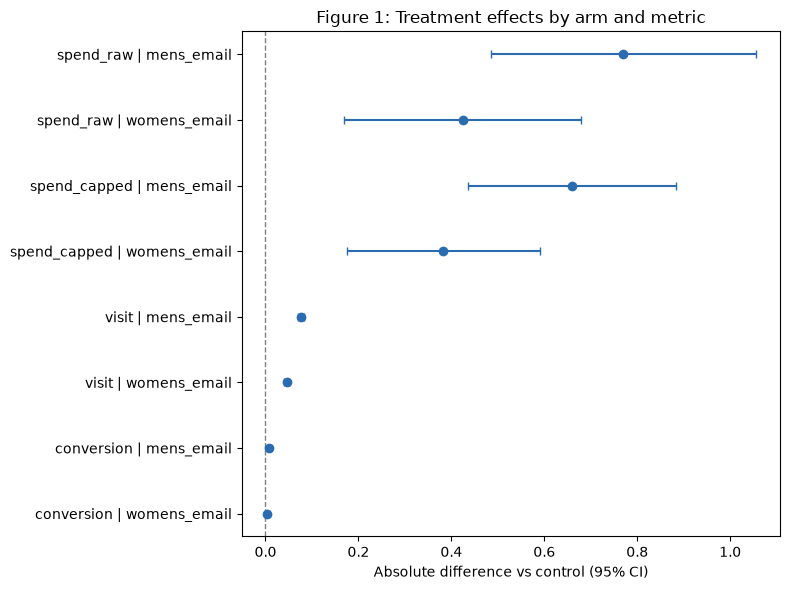

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
labels = [f"{r.metric} | {r.arm}" for r in effects.itertuples()]
y_pos = np.arange(len(effects))[::-1]

ax.errorbar(
    effects["diff"], y_pos,
    xerr=[effects["diff"] - effects["ci_low"], effects["ci_high"] - effects["diff"]],
    fmt="o", color="#2b6cb0", ecolor="#2b6cb0", capsize=3,
)
ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels)
ax.set_xlabel("Absolute difference vs control (95% CI)")
ax.set_title("Figure 1: Treatment effects by arm and metric")
plt.tight_layout()
plt.savefig("../reports/figures/fig1_forest_plot.png", dpi=150)
plt.show()

## A4 + A5. Power calculation, CUPED and CUPAC

A4 asks two questions (before/after the test), and the "after CUPED" line of Figure 2
needs the CUPED variance reduction from A5, so both are computed together here.

### A4a. Before the test: sample size needed for 80% power, +10% relative lift in spend

In [9]:
sigma_control = control.spend.std(ddof=1)
mean_control_spend = control.spend.mean()
mde_abs_10pct = 0.10 * mean_control_spend

n_needed = n_per_arm(sigma_control, mde_abs_10pct)
print(f"Control spend: mean={mean_control_spend:.4f}, sd={sigma_control:.4f}")
print(f"Absolute MDE for a 10% relative lift: {mde_abs_10pct:.4f}")
print(f"Required n per arm for 80% power: {n_needed:,}")

Control spend: mean=0.6528, sd=11.5882
Absolute MDE for a 10% relative lift: 0.0653
Required n per arm for 80% power: 494,680


### A4b. After the test: minimum detectable effect with the sample we actually had

In [10]:
n_actual = len(control)
mde_abs_actual = mde(sigma_control, n_actual)
mde_rel_actual = mde_abs_actual / mean_control_spend
print(f"Actual n per arm (control): {n_actual:,}")
print(f"Achieved MDE (absolute): {mde_abs_actual:.4f}")
print(f"Achieved MDE (relative to control mean): {mde_rel_actual:.2%}")

Actual n per arm (control): 21,306
Achieved MDE (absolute): 0.3145
Achieved MDE (relative to control mean): 48.18%


### A5. CUPED

theta is estimated on all arms pooled (valid because `history` is measured before
treatment and can't be affected by it).

In [11]:
theta_spend = np.cov(df.spend.values, df.history.values, ddof=1)[0, 1] / np.var(df.history.values, ddof=1)
df["spend_cuped"] = cuped(df.spend.values, df.history.values)

var_reduction_spend_cuped = variance_reduction(df.spend.values, df.spend_cuped.values)
rho_spend_history = np.corrcoef(df.spend, df.history)[0, 1]
print(f"theta (spend ~ history): {theta_spend:.6f}")
print(f"correlation(spend, history): {rho_spend_history:.4f}")
print(f"CUPED variance reduction for spend: {var_reduction_spend_cuped:.2%}")

theta (spend ~ history): 0.001275
correlation(spend, history): 0.0217
CUPED variance reduction for spend: 0.05%


In [12]:
theta_visit = np.cov(df.visit.values.astype(float), df.history.values, ddof=1)[0, 1] / np.var(df.history.values, ddof=1)
df["visit_cuped"] = cuped(df.visit.values.astype(float), df.history.values)
var_reduction_visit_cuped = variance_reduction(df.visit.values.astype(float), df.visit_cuped.values)
print(f"CUPED variance reduction for visit (covariate=history): {var_reduction_visit_cuped:.2%}")

CUPED variance reduction for visit (covariate=history): 0.42%


### CUPAC: cross-fitted ML prediction of spend from all pre-period features

In [13]:
from sklearn.model_selection import KFold
from sklearn.ensemble import HistGradientBoostingRegressor

pre_cols = ["recency", "history", "mens", "womens", "zip_code", "newbie", "channel"]
X = pd.get_dummies(df[pre_cols], drop_first=True)

pred_spend = np.zeros(len(df))
for tr, te in KFold(5, shuffle=True, random_state=42).split(X):
    m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42)
    m.fit(X.iloc[tr], df["spend"].iloc[tr])
    pred_spend[te] = m.predict(X.iloc[te])

df["spend_cupac"] = cuped(df["spend"].values, pred_spend)
var_reduction_spend_cupac = variance_reduction(df.spend.values, df.spend_cupac.values)
rho_spend_pred = np.corrcoef(df.spend, pred_spend)[0, 1]
print(f"correlation(spend, CUPAC prediction): {rho_spend_pred:.4f}")
print(f"CUPAC variance reduction for spend: {var_reduction_spend_cupac:.2%}")

correlation(spend, CUPAC prediction): 0.0138
CUPAC variance reduction for spend: 0.02%


In [14]:
pred_visit = np.zeros(len(df))
y_visit = df["visit"].values.astype(float)
for tr, te in KFold(5, shuffle=True, random_state=42).split(X):
    m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42)
    m.fit(X.iloc[tr], y_visit[tr])
    pred_visit[te] = m.predict(X.iloc[te])

df["visit_cupac"] = cuped(y_visit, pred_visit)
var_reduction_visit_cupac = variance_reduction(y_visit, df.visit_cupac.values)
print(f"CUPAC variance reduction for visit: {var_reduction_visit_cupac:.2%}")

CUPAC variance reduction for visit: 2.27%


### CUPED/CUPAC-adjusted treatment effects, and the summary table

In [15]:
def effect_row(metric, method, y_col):
    rows = []
    for arm_name in ["mens_email", "womens_email"]:
        y_t = df.loc[df.arm == arm_name, y_col]
        y_c = df.loc[df.arm == "control", y_col]
        d, se, ci, p = diff_ci(y_t, y_c)
        rows.append({
            "metric": metric, "method": method, "arm": arm_name,
            "effect": d, "se": se, "ci_low": ci[0], "ci_high": ci[1], "p_raw": p,
        })
    return rows

summary_rows = []
summary_rows += effect_row("spend", "raw", "spend")
summary_rows += effect_row("spend", "CUPED (history)", "spend_cuped")
summary_rows += effect_row("spend", "CUPAC (all pre-period features)", "spend_cupac")
summary_rows += effect_row("visit", "raw", "visit")
summary_rows += effect_row("visit", "CUPED (history)", "visit_cuped")
summary_rows += effect_row("visit", "CUPAC (all pre-period features)", "visit_cupac")

var_reduction_map = {
    ("spend", "raw"): 0.0,
    ("spend", "CUPED (history)"): var_reduction_spend_cuped,
    ("spend", "CUPAC (all pre-period features)"): var_reduction_spend_cupac,
    ("visit", "raw"): 0.0,
    ("visit", "CUPED (history)"): var_reduction_visit_cuped,
    ("visit", "CUPAC (all pre-period features)"): var_reduction_visit_cupac,
}

summary = pd.DataFrame(summary_rows)
summary["variance_reduction"] = summary.apply(lambda r: var_reduction_map[(r.metric, r.method)], axis=1)
summary["equivalent_sample_saved"] = summary["variance_reduction"]
summary[["metric", "method", "arm", "effect", "se", "ci_low", "ci_high", "p_raw",
         "variance_reduction", "equivalent_sample_saved"]]

,metric,method,arm,effect,se,ci_low,ci_high,p_raw,variance_reduction,equivalent_sample_saved
0,spend,raw,mens_email,0.7698,0.1452,0.4851,1.0545,1.1571e-07,0.0000,0.0000
1,spend,raw,womens_email,0.4244,0.1303,0.1690,0.6799,1.1285e-03,0.0000,0.0000
2,spend,CUPED (history),mens_email,0.7673,0.1452,0.4827,1.0520,1.2630e-07,0.0005,0.0005
3,spend,CUPED (history),womens_email,0.4223,0.1303,0.1669,0.6777,1.1921e-03,0.0005,0.0005
4,spend,CUPAC (all pre-period features),mens_email,0.7678,0.1452,0.4832,1.0525,1.2460e-07,0.0002,0.0002
5,spend,CUPAC (all pre-period features),womens_email,0.4256,0.1303,0.1702,0.6810,1.0916e-03,0.0002,0.0002
6,visit,raw,mens_email,0.0766,0.0034,0.0700,0.0832,0.0000e+00,0.0000,0.0000
7,visit,raw,womens_email,0.0452,0.0032,0.0389,0.0516,0.0000e+00,0.0000,0.0000
8,visit,CUPED (history),mens_email,0.0764,0.0034,0.0698,0.0830,0.0000e+00,0.0042,0.0042
9,visit,CUPED (history),womens_email,0.0451,0.0032,0.0388,0.0514,0.0000e+00,0.0042,0.0042


**Figure 2: required n per arm vs relative MDE, raw spend vs CUPED-adjusted spend.**

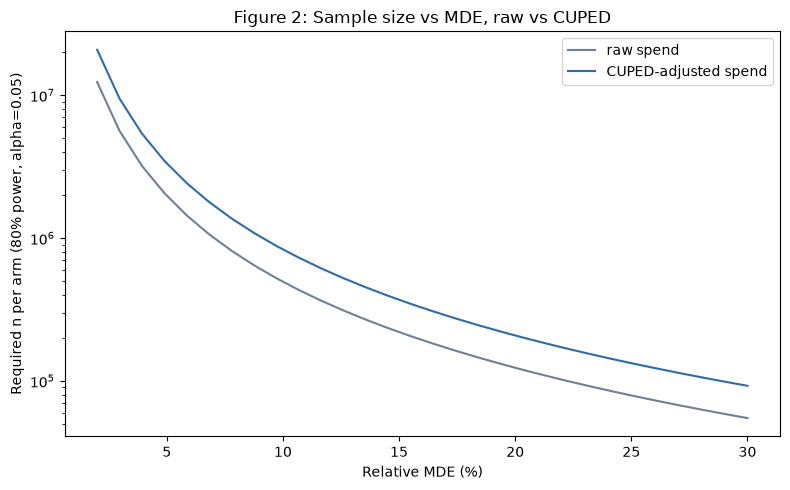

In [16]:
rel_mdes = np.linspace(0.02, 0.30, 30)
n_raw = [n_per_arm(sigma_control, r * mean_control_spend) for r in rel_mdes]

sigma_cuped = df.spend_cuped.std(ddof=1)
n_cuped = [n_per_arm(sigma_cuped, r * mean_control_spend) for r in rel_mdes]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(rel_mdes * 100, n_raw, label="raw spend", color="#718096")
ax.plot(rel_mdes * 100, n_cuped, label="CUPED-adjusted spend", color="#2b6cb0")
ax.set_xlabel("Relative MDE (%)")
ax.set_ylabel("Required n per arm (80% power, alpha=0.05)")
ax.set_yscale("log")
ax.set_title("Figure 2: Sample size vs MDE, raw vs CUPED")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/fig2_power_curve.png", dpi=150)
plt.show()

## A6. A/A validation

Using the control arm only, split it into two fake arms 1,000 times. For each split,
run the raw test and the CUPED test and record the p-value and SE.

In [17]:
n_sims = 1000
control_spend_vals = control.spend.values
control_history_vals = control.history.values
n_control = len(control_spend_vals)

p_raw_list, p_cuped_list = [], []
se_raw_list, se_cuped_list = [], []

for i in range(n_sims):
    perm = rng.permutation(n_control)
    half = n_control // 2
    idx_a, idx_b = perm[:half], perm[half:]

    y_a, y_b = control_spend_vals[idx_a], control_spend_vals[idx_b]
    _, se_raw, _, p_raw = diff_ci(y_a, y_b)
    p_raw_list.append(p_raw)
    se_raw_list.append(se_raw)

    x_all = control_history_vals
    y_all = control_spend_vals
    theta_i = np.cov(y_all, x_all, ddof=1)[0, 1] / np.var(x_all, ddof=1)
    y_adj = y_all - theta_i * (x_all - x_all.mean())
    y_adj_a, y_adj_b = y_adj[idx_a], y_adj[idx_b]
    _, se_cuped, _, p_cuped = diff_ci(y_adj_a, y_adj_b)
    p_cuped_list.append(p_cuped)
    se_cuped_list.append(se_cuped)

p_raw_arr = np.array(p_raw_list)
p_cuped_arr = np.array(p_cuped_list)

fpr_raw = (p_raw_arr < 0.05).mean()
fpr_cuped = (p_cuped_arr < 0.05).mean()
mean_se_raw = np.mean(se_raw_list)
mean_se_cuped = np.mean(se_cuped_list)

print(f"A/A false-positive rate, raw:   {fpr_raw:.3%}")
print(f"A/A false-positive rate, CUPED: {fpr_cuped:.3%}")
print(f"Mean SE, raw:   {mean_se_raw:.5f}")
print(f"Mean SE, CUPED: {mean_se_cuped:.5f}")
print(f"Implied variance reduction from A/A SEs: {1 - (mean_se_cuped/mean_se_raw)**2:.2%}")

A/A false-positive rate, raw:   4.900%
A/A false-positive rate, CUPED: 5.100%
Mean SE, raw:   0.15878
Mean SE, CUPED: 0.15876
Implied variance reduction from A/A SEs: 0.02%


**Figure 3: p-value histograms for raw and CUPED A/A splits (both should look flat / uniform).**

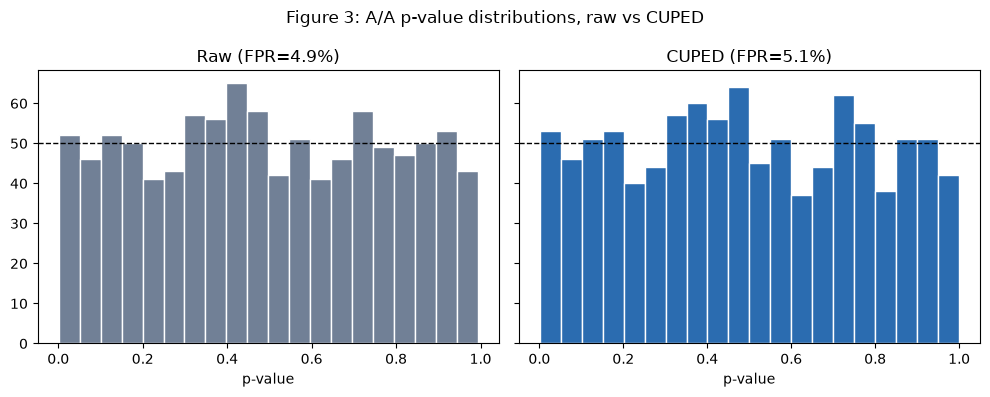

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
axes[0].hist(p_raw_arr, bins=20, color="#718096", edgecolor="white")
axes[0].axhline(n_sims / 20, color="black", linestyle="--", linewidth=1)
axes[0].set_title(f"Raw (FPR={fpr_raw:.1%})")
axes[0].set_xlabel("p-value")

axes[1].hist(p_cuped_arr, bins=20, color="#2b6cb0", edgecolor="white")
axes[1].axhline(n_sims / 20, color="black", linestyle="--", linewidth=1)
axes[1].set_title(f"CUPED (FPR={fpr_cuped:.1%})")
axes[1].set_xlabel("p-value")

fig.suptitle("Figure 3: A/A p-value distributions, raw vs CUPED")
plt.tight_layout()
plt.savefig("../reports/figures/fig3_aa_pvalues.png", dpi=150)
plt.show()

## A7. Decision memo

(Filled in with the real numbers computed above — see the printed outputs.)

In [19]:
mens_spend_eff = effects.query("metric == 'spend_raw' and arm == 'mens_email'").iloc[0]
womens_spend_eff = effects.query("metric == 'spend_raw' and arm == 'womens_email'").iloc[0]
per_100k_mens = mens_spend_eff["diff"] * 100_000
per_100k_mens_lo = mens_spend_eff["ci_low"] * 100_000
per_100k_mens_hi = mens_spend_eff["ci_high"] * 100_000

print("Decision memo inputs:")
print(f"Mens e-mail spend effect: {mens_spend_eff['diff']:.4f} "
      f"[{mens_spend_eff['ci_low']:.4f}, {mens_spend_eff['ci_high']:.4f}], "
      f"p_holm={mens_spend_eff['p_holm']:.4f}")
print(f"Womens e-mail spend effect: {womens_spend_eff['diff']:.4f} "
      f"[{womens_spend_eff['ci_low']:.4f}, {womens_spend_eff['ci_high']:.4f}], "
      f"p_holm={womens_spend_eff['p_holm']:.4f}")
print(f"Projected impact of Mens e-mail per 100,000 customers: "
      f"${per_100k_mens:,.0f} [${per_100k_mens_lo:,.0f}, ${per_100k_mens_hi:,.0f}]")

Decision memo inputs:
Mens e-mail spend effect: 0.7698 [0.4851, 1.0545], p_holm=0.0000
Womens e-mail spend effect: 0.4244 [0.1690, 0.6799], p_holm=0.0011
Projected impact of Mens e-mail per 100,000 customers: $76,983 [$48,515, $105,451]


**Decision memo (to fill into the README with the numbers printed above):**

- Ship: [state which promotion, if any, has a statistically significant, Holm-corrected
  positive effect on spend].
- Expected impact: $[X] per 100,000 customers, 95% CI [$Y, $Z] (2-week window).
- Caveats: effect measured over a 2-week window only; novelty effects from a first-time
  promotion are not separated from a steady-state effect; long-run retention impact is
  not measured.
- Next test: a longer observation window, and a CUPAC-powered test sized to the
  achieved MDE above so a smaller true effect could still be detected.

In [20]:
df[["spend", "spend_capped", "spend_cuped", "spend_cupac",
    "visit", "visit_cuped", "visit_cupac"]].to_parquet("../data/promo_ab_processed.parquet")
summary.to_csv("../reports/figures/part_a_summary_table.csv", index=False)
print("Saved processed data and summary table.")

Saved processed data and summary table.
